# 1 · Explore the data

A model can only learn what is in the data, so we look first. Each section asks one
question, answers it with a small measurement, and ends with **→ For the model**: what we
will do differently because of it. The second notebook, `2-build-model.ipynb`, puts those
ideas to the test.

**How to read this:** the text and the pictures matter most. Code cells that start with
`# Helper:` do one job, described on that first line; you can trust them without reading
every line. It runs in about a minute.

In [1]:
import matplotlib.pyplot as plt
import torch
from torch.nn import functional as F

from eurosat import data  # the only course code we use: it loads the images

plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False})

full = data.train_set()
images, labels, names = full.images, full.labels, data.CLASSES
print(f"images: {tuple(images.shape)} {images.dtype}, {images.numel() / 1e6:.0f} MB")
print(f"labels: {tuple(labels.shape)} {labels.dtype}, from {labels.min()} to {labels.max()}")

images: (21600, 3, 64, 64) torch.uint8, 265 MB
labels: (21600,) torch.int64, from 0 to 9


A *tensor* is PyTorch's word for a grid of numbers. The shape `(21600, 3, 64, 64)` reads:
21,600 images, each with 3 colors (red, green, blue), 64 rows and 64 columns of pixels.
Every number is a byte, from 0 (dark) to 255 (bright). A network wants decimal numbers
(floats), which take 4 times the memory, about 1 GB here, so we convert one batch at a time.

To judge anything we *train*, we test it on images it did not learn from. `split_for_check`
puts 20% of the images aside for checking. Notebook 2 uses the same split (`seed=1`).

In [2]:
fit, check = data.split_for_check(full, seed=1)
print(f"{len(fit):,} images to learn from, {len(check):,} to check with")

17,280 images to learn from, 4,320 to check with


**Learn more:** [Tensors](https://pytorch.org/tutorials/beginner/basics/tensorqs_tutorial.html)
(PyTorch tutorial) · [EuroSAT](https://arxiv.org/abs/1709.00029) (the paper that made this
dataset)

## Are the classes balanced?

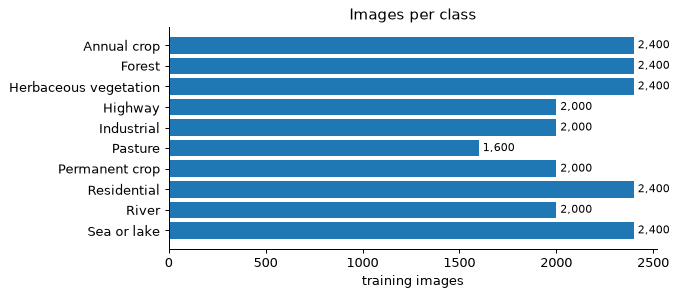

largest class / smallest class: 1.50
always answering the largest class: 11.1% accuracy


In [3]:
counts = torch.bincount(labels, minlength=len(names))  # how many images of each class
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.barh(names, counts, color="tab:blue")
ax.invert_yaxis()
for y, n in enumerate(counts.tolist()):
    ax.text(n, y, f" {n:,}", va="center", fontsize=9)
ax.set_xlabel("training images")
ax.set_title("Images per class")
plt.show()

print(f"largest class / smallest class: {counts.max() / counts.min():.2f}")
print(f"always answering the largest class: {counts.max() / counts.sum():.1%} accuracy")

The largest class has 1.5 times as many images as the smallest. That is mild: a model that
always gives the most common answer gets only 11% right.

**→ For the model:** accuracy (the share of right answers) is a fair score here, and we can
train with the standard loss, without giving rare classes extra weight.

## What do the classes look like?

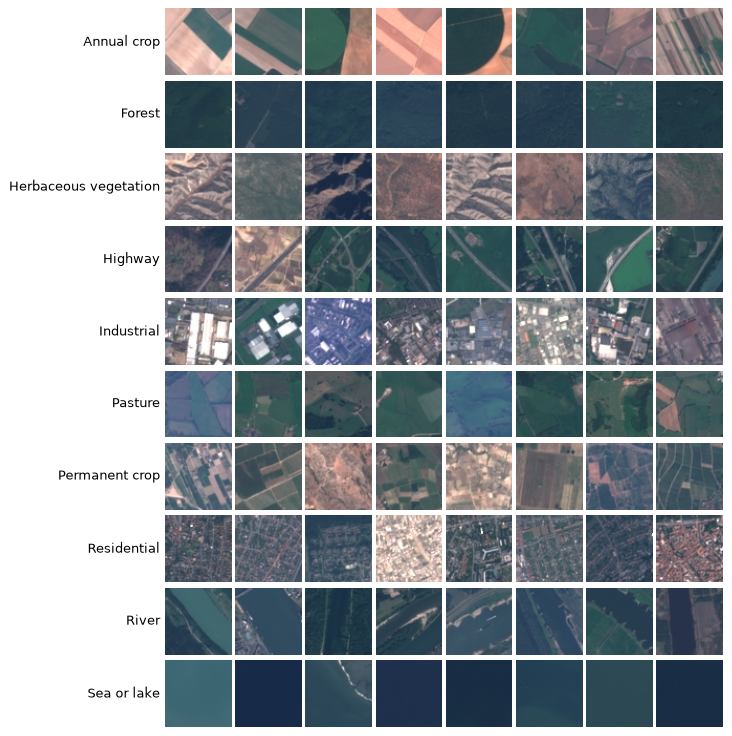

In [4]:
# Helper: show 8 random images of every class, one class per row.
generator = torch.Generator().manual_seed(0)
fig, axes = plt.subplots(10, 8, figsize=(8, 10.4), gridspec_kw={"wspace": 0.05, "hspace": 0.05})
for k, row in enumerate(axes):
    members = (labels == k).nonzero().flatten()
    picks = members[torch.randperm(len(members), generator=generator)[:8]]
    for ax, i in zip(row, picks, strict=True):
        ax.imshow(images[i].permute(1, 2, 0))  # matplotlib wants (rows, columns, colors)
        ax.set_xticks([])
        ax.set_yticks([])
        ax.spines[:].set_visible(False)
    row[0].set_ylabel(names[k], rotation=0, ha="right", va="center", fontsize=10)
plt.show()

What to notice:

- The photos are **dark and low in contrast**: they are what the satellite measured, not
  edited to look nice.
- Some classes stand out by **color and smoothness**: Sea or lake is flat dark blue, Forest is
  dark green with almost no structure.
- Some stand out by **shape**: Highway and River are long lines across other land.
  Residential and Industrial are dense small blocks; Industrial has bigger, brighter roofs.
- Four classes are **all fields**: Annual crop, Permanent crop, Pasture and Herbaceous
  vegetation. Only the patterns inside the fields tell them apart. Expect these to be hard.

## How far does color alone go?

Let's try the simplest classifier we can think of. Each image becomes just 6 numbers: how
bright its red, green and blue are on average, and how much each one varies. A tiny model
learns from those 6 numbers which class is likely (it adds them up with a weight per class:
this is called *logistic regression*). It cannot see shapes at all, so whatever it gets right,
color alone explains.

In [5]:
def color_features(images):
    # Helper: 6 numbers per image: the average and the spread of red, green and blue.
    x = images.float() / 255
    return torch.cat([x.mean((2, 3)), x.std((2, 3))], dim=1)


def fit_logistic_regression(x, y):
    # Helper: the simplest classifier, one weight per (number, class), fitted in seconds.
    layer = torch.nn.Linear(x.shape[1], len(names))
    optimizer = torch.optim.LBFGS(layer.parameters(), max_iter=300)

    def closure():
        optimizer.zero_grad()
        loss = F.cross_entropy(layer(x), y)
        loss.backward()
        return loss

    optimizer.step(closure)
    return layer


x_fit, x_check = color_features(fit.images), color_features(check.images)
mean, spread = x_fit.mean(0), x_fit.std(0)  # put all 6 numbers on the same scale
color_model = fit_logistic_regression((x_fit - mean) / spread, fit.labels)
with torch.no_grad():
    color_guess = color_model((x_check - mean) / spread).argmax(1)
print(f"color only: {(color_guess == check.labels).float().mean():.1%} right")

color only: 67.0% right


A *confusion matrix* shows **which** mistakes a model makes. Each row is a true class; the
numbers say where its check images ended up, in percent. The diagonal is right answers;
everything else is a mix-up.

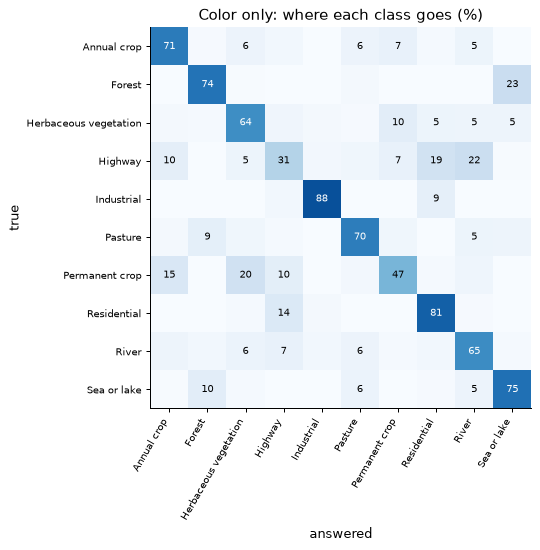

In [6]:
def plot_confusion(truth, guess, title):
    # Helper: draw the confusion matrix, in percent of each row.
    matrix = torch.zeros(len(names), len(names))
    matrix.index_put_((truth, guess), torch.ones(len(truth)), accumulate=True)
    matrix = 100 * matrix / matrix.sum(1, keepdim=True)
    fig, ax = plt.subplots(figsize=(6, 5.5))
    ax.imshow(matrix, cmap="Blues", vmin=0, vmax=100)
    for i in range(len(names)):
        for j in range(len(names)):
            if matrix[i, j] >= 5:
                ax.text(j, i, f"{matrix[i, j]:.0f}", ha="center", va="center", fontsize=8,
                        color="white" if matrix[i, j] > 50 else "black")  # fmt: skip
    ax.set_xticks(range(len(names)), names, rotation=60, ha="right", fontsize=8)
    ax.set_yticks(range(len(names)), names, fontsize=8)
    ax.set_xlabel("answered")
    ax.set_ylabel("true")
    ax.set_title(title)
    plt.show()


plot_confusion(check.labels, color_guess, "Color only: where each class goes (%)")

Color alone gets **67%** right, six times better than always giving the most common answer.
Its mistakes show what a network must learn *beyond* color:

- **Forest → Sea or lake (23%)**: both are dark. Only texture tells them apart.
- **Highway (31% right)** looks like Residential or River by color. A road is a *shape*.
- **Permanent crop (47% right)** mixes with Herbaceous vegetation and Annual crop: fields of the
  same colors with different patterns.

**→ For the model:** color carries a lot of the answer, so we will not randomly change colors
during training (a common trick called *color jitter*): it would hide a strong clue. And
when we study the network's mistakes in notebook 2, these pairs are the first suspects.

**Learn more:** [Logistic regression](https://www.youtube.com/watch?v=yIYKR4sgzI8)
(StatQuest video) · [Confusion matrix](https://en.wikipedia.org/wiki/Confusion_matrix)
(Wikipedia)

## Should we normalize the colors?

average pixel (red, green, blue): [0.35, 0.38, 0.41]
spread        (red, green, blue): [0.2, 0.14, 0.12]


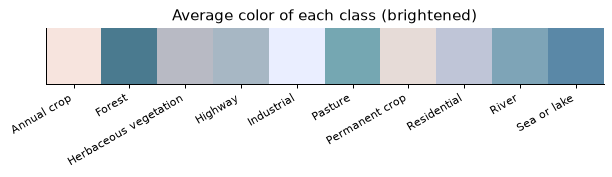

In [7]:
average = x_fit[:, :3].mean(0)
spread = ((x_fit[:, 3:] ** 2 + x_fit[:, :3] ** 2).mean(0) - average**2).sqrt()
print("average pixel (red, green, blue):", [round(v, 2) for v in average.tolist()])
print("spread        (red, green, blue):", [round(v, 2) for v in spread.tolist()])

class_colors = torch.stack([x_fit[fit.labels == k, :3].mean(0) for k in range(len(names))])
fig, ax = plt.subplots(figsize=(8, 1.6))
ax.imshow(class_colors[None] / class_colors.max())  # brightened, so the colors are visible
ax.set_xticks(range(len(names)), names, rotation=30, ha="right", fontsize=9)
ax.set_yticks([])
ax.set_title("Average color of each class (brightened)")
plt.show()

On a scale of 0 to 1, the average pixel is about 0.35 to 0.41, and red varies most. Many
tutorials *normalize* the input: subtract the average and divide by the spread, so every
color is centered on 0. Networks learn more easily from numbers of that size.

**→ For the model:** the network in notebook 2 has a layer right after its first one that
does this rescaling by itself, while it learns (*batch normalization*). So we feed the images
as they are, and check inside the network that its numbers stay in a healthy range.

## How much fine detail is there?

A network's first layer slides a small 3×3 window over the image. If the window moves 2
pixels at a time instead of 1 (*stride 2*), every layer after it has 4 times fewer positions
to compute, so the network gets about 4 times cheaper. Would that lose important detail?

To find out, we split each image into patterns of different sizes, from large smooth areas
down to stripes 2 pixels wide, and measure how much of the image is in each size. (The tool
for this is the *Fourier transform*. The video below shows the idea beautifully; you do not
need it to read the plot.)

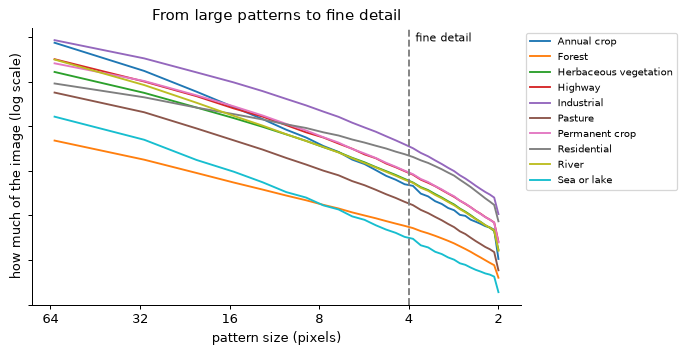

Residential             4.7% of the image is detail smaller than 4 pixels
Forest                  3.6% of the image is detail smaller than 4 pixels
Industrial              1.0% of the image is detail smaller than 4 pixels
Herbaceous vegetation   1.0% of the image is detail smaller than 4 pixels
Permanent crop          0.9% of the image is detail smaller than 4 pixels
Pasture                 0.9% of the image is detail smaller than 4 pixels
Highway                 0.8% of the image is detail smaller than 4 pixels
Sea or lake             0.7% of the image is detail smaller than 4 pixels
River                   0.6% of the image is detail smaller than 4 pixels
Annual crop             0.2% of the image is detail smaller than 4 pixels


In [8]:
def amount_by_pattern_size(images, bins=32):
    # Helper: for each image, how much of it is made of patterns of each size (Fourier).
    gray = images.float().mean(1)  # brightness only
    gray = gray - gray.mean((1, 2), keepdim=True)  # ignore the overall brightness
    power = torch.fft.fft2(gray).abs() ** 2
    f = torch.fft.fftfreq(gray.shape[-1])
    radius = (f[:, None] ** 2 + f[None, :] ** 2).sqrt().clamp(max=0.5)
    which = (radius / 0.5 * (bins - 1)).round().long().flatten()
    total = torch.zeros(len(images), bins).index_add_(1, which, power.flatten(1))
    count = torch.zeros(bins).index_add_(0, which, torch.ones_like(which, dtype=torch.float))
    return total / count


size = 1 / torch.linspace(0, 0.5, 32)[1:]  # pattern size in pixels: 62 down to 2
fine_share = {}
fig, ax = plt.subplots(figsize=(7, 4))
for k, name in enumerate(names):
    amount = torch.cat([amount_by_pattern_size(x) for x in images[labels == k].split(1000)]).mean(0)
    ax.loglog(size, amount[1:], label=name, color=plt.cm.tab10(k))
    fine_share[name] = (amount[1:][size < 4].sum() / amount[1:].sum()).item()
ax.axvline(4, color="gray", ls="--")
ax.text(3.8, 0.95, "fine detail", transform=ax.get_xaxis_transform(), fontsize=9)
ax.invert_xaxis()
ax.set_xticks([64, 32, 16, 8, 4, 2], ["64", "32", "16", "8", "4", "2"])
ax.minorticks_off()
ax.tick_params(axis="y", labelleft=False)
ax.set_xlabel("pattern size (pixels)")
ax.set_ylabel("how much of the image (log scale)")
ax.set_title("From large patterns to fine detail")
ax.legend(fontsize=8, bbox_to_anchor=(1, 1), loc="upper left")
plt.show()

for name, share in sorted(fine_share.items(), key=lambda item: -item[1]):
    print(f"{name:22} {share:5.1%} of the image is detail smaller than 4 pixels")

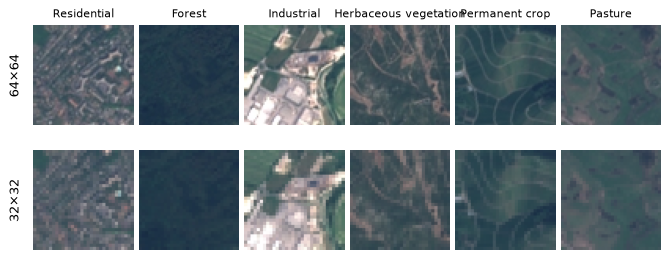

In [9]:
# Helper: the classes with the most fine detail, at full size and at half size.
fig, axes = plt.subplots(2, 6, figsize=(9, 3.3), gridspec_kw={"wspace": 0.05})
for column, k in enumerate(sorted(range(10), key=lambda k: -fine_share[names[k]])[:6]):
    i = (labels == k).nonzero()[0].item()
    full_size = images[i].float()[None] / 255
    half_size = F.interpolate(F.avg_pool2d(full_size, 2), scale_factor=2, mode="nearest")
    for row, picture in enumerate((full_size, half_size)):
        axes[row, column].imshow(picture[0].permute(1, 2, 0))
        axes[row, column].axis("off")
    axes[0, column].set_title(names[k], fontsize=9)
axes[0, 0].text(-8, 32, "64×64", rotation=90, va="center", ha="right")
axes[1, 0].text(-8, 32, "32×32", rotation=90, va="center", ha="right")
plt.show()

Every class is mostly large patterns: **less than 5% of any image is detail smaller than 4
pixels**. Residential and Forest have the most. At half size, small buildings and tree
crowns blur, but the layout of every scene survives.

**→ For the model:** stride 2 looks like a big saving for a small loss (maybe a little for
Residential and Industrial). It does not even throw pixels away: the 3×3 windows still
overlap and see every pixel; they just report from every second position. Notebook 2
measures both versions, giving each the same training time.

**Learn more:** [But what is a convolution?](https://www.youtube.com/watch?v=KuXjwB4LzSA)
(3Blue1Brown video) · [But what is the Fourier transform?](https://www.youtube.com/watch?v=spUNpyF58BY)
(3Blue1Brown video)

## Do the images have an "up"?

A photo taken from straight above seems to have no up or down. If so, a turned or mirrored
image is just as real as the original, and we could turn and mirror our training images to
get 8 times as many for free. This trick is called *data augmentation*. Let's check before
we assume.

For each image we find the direction its edges mostly run in (0° = left to right, 90° = up
and down) and how strongly: 0 if edges run every which way, 1 if they all run the same way.
(The method is called the *structure tensor*; its math is not needed to read the results.)

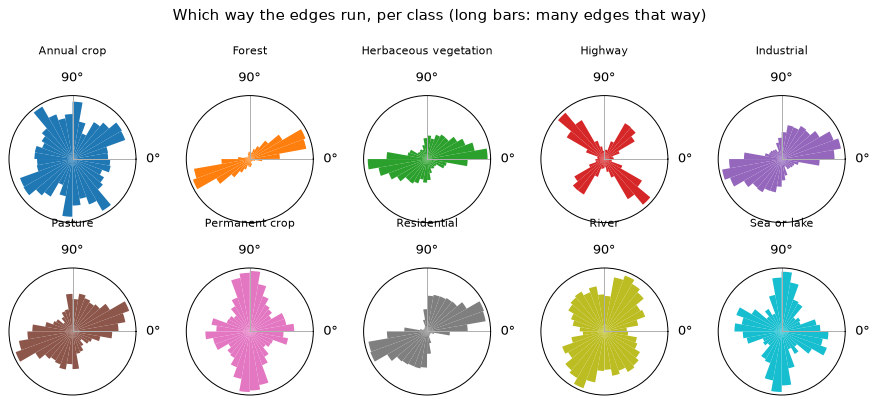

In [10]:
def edge_direction(images):
    # Helper: the main edge direction of each image (-90° to 90°), and how strong it is (0 to 1).
    gray = images.float().mean(1, keepdim=True)
    sobel = torch.tensor([[-1.0, 0, 1], [-2, 0, 2], [-1, 0, 1]])  # finds left-right change
    gx = F.conv2d(gray, sobel[None, None])
    gy = -F.conv2d(gray, sobel.T[None, None])  # up-down change (minus: rows count downward)
    xx, yy, xy = (gx * gx).sum((1, 2, 3)), (gy * gy).sum((1, 2, 3)), (gx * gy).sum((1, 2, 3))
    change = 0.5 * torch.atan2(2 * xy, xx - yy)  # the direction brightness changes most
    strength = ((xx - yy) ** 2 + 4 * xy**2).sqrt() / (xx + yy + 1e-9)
    edge = torch.rad2deg(change) + 90  # edges run across that direction
    return (edge + 90) % 180 - 90, strength


pieces = [edge_direction(x) for x in images.split(2000)]  # 2,000 images at a time
angle = torch.cat([a for a, _ in pieces])
strength = torch.cat([s for _, s in pieces])

fig, axes = plt.subplots(2, 5, figsize=(10, 4.4), subplot_kw={"projection": "polar"})
for k, ax in enumerate(axes.flat):
    a, w = torch.deg2rad(angle[labels == k]), strength[labels == k]
    # An edge at 30° is also an edge at 210°, so each one is drawn both ways.
    ax.hist(torch.cat([a, a + torch.pi]), bins=36, weights=torch.cat([w, w]), color=plt.cm.tab10(k))
    ax.set_title(names[k], fontsize=9, pad=14)
    ax.set_yticks([])
    ax.set_xticks(torch.deg2rad(torch.tensor([0.0, 90])), ["0°", "90°"])
fig.suptitle("Which way the edges run, per class (long bars: many edges that way)", y=1.01)
plt.tight_layout()
plt.show()

Several circles are far from round. To put one number on "leans one way", we turn each
image's direction into an arrow and average the arrows. If they point every way, they cancel
out and the average is short (near 0). If they agree, it is long (up to 1). With about 2,000
images per class, pure chance would give about 0.02.

In [11]:
print(f"{'class':22} {'agreement':>9}  {'direction':>9}")
for k, name in enumerate(names):
    doubled = 2 * torch.deg2rad(angle[labels == k])  # doubled, so 0° and 180° agree
    arrow = torch.complex(doubled.cos(), doubled.sin()).mean()
    bar = "#" * round(arrow.abs().item() * 40)
    print(f"{name:22} {arrow.abs():9.2f}  {torch.rad2deg(arrow.angle()) / 2:8.0f}°  {bar}")

class                  agreement  direction
Annual crop                 0.04        77°  ##
Forest                      0.60        27°  ########################
Herbaceous vegetation       0.25        29°  ##########
Highway                     0.08       -58°  ###
Industrial                  0.30        34°  ############
Pasture                     0.19        34°  ########
Permanent crop              0.10        78°  ####
Residential                 0.41        44°  #################
River                       0.08        78°  ###
Sea or lake                 0.28        85°  ###########


The answer is "partly", and it surprised us:

- **Textured classes all lean the same way, about 30°**: Forest most (0.60), then Residential,
  Industrial, Herbaceous vegetation and Pasture. That is most likely the **sunlight**: the
  satellite passes over Europe at about the same time every morning, so the sun lights every
  slope, tree and roof from the same side, and their shadows line up.
- **Roads, rivers and fields point every way** (Annual crop, Highway, Permanent crop, River:
  0.10 or less). For those, a turned image is as real as the original.

**→ For the model:** turning and mirroring gives more varied training images, but some are
lit from sides that never occur in the test images, and the network must spend some of its
few parameters on ignoring the light. Whether that helps or hurts is a question for an
experiment, not a rule. Notebook 2 trains both ways and compares.

**Learn more:** [Sun-synchronous orbit](https://en.wikipedia.org/wiki/Sun-synchronous_orbit)
(why the satellite always passes at the same time; Wikipedia) ·
[Structure tensor](https://en.wikipedia.org/wiki/Structure_tensor) (for the curious; Wikipedia)

## Are there duplicates?

If the same place appears twice, one copy can end up among the images we learn from and the
other among the check images. The model then gets that check image right because it has seen
it, and the check score looks better than it really is.

Our first attempt compared tiny thumbnails and flagged 1,500 "duplicates", nearly all of them
open water: two patches of calm sea *are* almost identical images, without being the same
place. So now we compare only the **pattern** of each image (brightness at 16×16, ignoring its
overall color and brightness) among images that have some texture. Two images with the same
pattern score a similarity of 1.

16,685 textured images. Similarity to the closest other image:
  50.0% of them are below 0.574
  99.0% of them are below 0.873
  99.9% of them are below 0.932


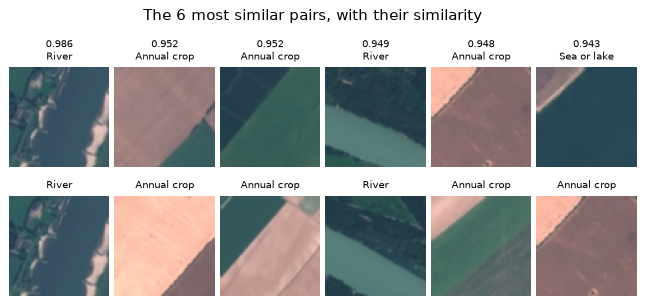

In [12]:
small = F.avg_pool2d(images.float().mean(1, keepdim=True), 4).flatten(1)  # 16x16 brightness
small = small - small.mean(1, keepdim=True)  # ignore the overall brightness
textured = small.std(1) > 5  # leave out flat water and the like
pattern = small / small.norm(dim=1, keepdim=True).clamp(min=1e-6)

# For every textured image, its most similar other image (2,000 at a time, to save memory).
best, twin = torch.full((len(pattern),), -1.0), torch.zeros(len(pattern), dtype=torch.long)
for rows in textured.nonzero().flatten().split(2000):
    similarity = pattern[rows] @ pattern[textured].T
    similarity[similarity > 0.9999] = -1  # not with itself
    best[rows], which = similarity.max(1)
    twin[rows] = textured.nonzero().flatten()[which]

print(f"{textured.sum():,} textured images. Similarity to the closest other image:")
for q in (0.5, 0.99, 0.999):
    print(f"  {q:.1%} of them are below {best[textured].quantile(q):.3f}")

fig, axes = plt.subplots(2, 6, figsize=(9, 3.4), gridspec_kw={"wspace": 0.05})
for column, i in enumerate(best.argsort(descending=True)[::2][:6].tolist()):
    for row, j in enumerate((i, twin[i].item())):
        axes[row, column].imshow(images[j].permute(1, 2, 0))
        axes[row, column].axis("off")
        axes[row, column].set_title(names[labels[j]], fontsize=8)
    axes[0, column].set_title(f"{best[i]:.3f}\n{names[labels[i]]}", fontsize=8)
fig.suptitle("The 6 most similar pairs, with their similarity", y=1.06)
plt.show()

Half of the textured images have nothing more similar than 0.57, and only 1 in 1,000 has
something above 0.93. Of the most similar pairs, only the first (two River images, 0.986)
looks like the same place; the others just share a layout, like one straight field edge.

**→ For the model:** one near-copy among 21,600 images cannot change a score, so the check
scores in notebook 2 can be trusted on this point.

**Learn more:** [Do we train on test data?](https://arxiv.org/abs/1902.00423) (a paper that
found near-duplicates between the training and test images of a famous dataset, CIFAR)

## What this means for the model

| What we found | → For the model | Tested in notebook 2? |
|---|---|---|
| Classes within 1.5× of each other; the most common answer gets 11% | Accuracy is a fair score; no extra weight for rare classes | no need |
| 265 MB as bytes, about 1 GB as floats | Convert one batch at a time | no need |
| Color alone gets 67% | Keep the colors as they are: no color jitter | reasoned here |
| Color mixes up Forest and Sea or lake, Highway, Permanent crop | These need texture and shape | yes: the mistakes |
| Less than 5% of any image is detail smaller than 4 pixels | Stride 2 may cost little and save 4× | yes: same training time |
| Textured classes lean ~30° (sunlight); roads, rivers, fields point every way | Turning and mirroring may help or hurt | yes: trained both ways |
| One near-copy among 16,685 textured images | No leak between learning and check images | no need |

Next: `2-build-model.ipynb`.